# Clustering degli Stili Tattici in Serie A con K-Means e DBSCAN
### Progetto per l'esame di Principi e Modelli della Percezione — Prof.ssa Elena Casiraghi

**Gruppo di lavoro:** Diego Cozzi (51299A), Mario Rovagnati (50644A), Matteo Dini (51073A)

---
### Indice della Pipeline:
1. **Cella 1:** Setup librerie, parametri e palette accessibile
2. **Cella 2:** Download dati reali Serie A (2005/06 – 2025/26) e creazione dataset `squadra-stagione`
3. **Cella 3:** Esplorazione iniziale (EDA) delle variabili di stile rispetto ai punti in classifica.
4. **Cella 4:** Normalizzazione con `StandardScaler` (confronto prima/dopo e peso nella distanza Euclidea).
5. **Cella 5:** Scelta del numero di cluster $k$ tramite Metodo del Gomito (WCSS) e Coefficiente di Silhouette.
6. **Cella 6:** Addestramento K-Means ($k=3$), profili dei centroidi e proiezione PCA 2D.
7. **Cella 7:** Confronto con DBSCAN (*k-distance graph*), rilevamento outlier/rumore e *Adjusted Rand Index*.
8. **Cella 8:** Validazione esterna (punti reali conquistati dai 3 cluster) ed esportazione finale in ZIP.

---
## 1. Setup, Palette Accessibile e Funzioni di Esportazione

In [1]:
import os, io, csv, requests, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

START_SEASON = 2005     # prima stagione con tiri, falli e cartellini completi
MIN_MATCHES  = 30       # scarta squadra-stagioni incomplete
USE_POINTS   = False    # False = i punti restano fuori dal clustering (validazione esterna)
K_OVERRIDE   = 3        # 3 fasce tattiche interpretabili (metti None per auto-silhouette)
EPS_OVERRIDE = None     # lascia None per calcolo automatico dal ginocchio del k-distance graph

EXPORT_DIR = "export_zip"
PLOTS_DIR  = f"{EXPORT_DIR}/plots"
DATA_DIR   = f"{EXPORT_DIR}/data"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

BLUE, ORANGE = "#1d4ed8", "#ea580c"
CLUSTER_COLORS = [BLUE, ORANGE, "#0f766e", "#7c3aed", "#ca8a04", "#be185d"]
NOISE_COLOR = "#111827"

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": "#374151",
    "axes.labelcolor": "#374151", "xtick.color": "#374151", "ytick.color": "#374151",
    "axes.grid": False, "legend.frameon": False,
})

def save_both(builder, name, clean=True):
    fig = builder()
    fig.savefig(f"{PLOTS_DIR}/{name}_con_guida.png", dpi=250, bbox_inches="tight", facecolor="white")
    plt.show()
    if clean:
        fig = builder()
        for ax in fig.axes:
            ax.set_title(""); ax.set_xlabel(""); ax.set_ylabel("")
            if ax.get_legend(): ax.get_legend().remove()
            for t in list(ax.texts): t.remove()
        if fig._suptitle is not None: fig._suptitle.set_text("")
        fig.savefig(f"{PLOTS_DIR}/{name}_clean.png", dpi=250, bbox_inches="tight", facecolor="white")
        plt.close(fig)
    print(f"Salvato: {name}_con_guida.png" + (" + _clean.png" if clean else ""))


---
## 2. Download Partite Serie A e Costruzione Dataset Squadra-Stagione

In [2]:
colonne_target = ["Date","HomeTeam","AwayTeam","FTHG","FTAG","FTR","HS","AS","HST","AST","HF","AF","HY","AY","HR","AR"]
colonne_num    = ["FTHG","FTAG","HS","AS","HST","AST","HF","AF","HY","AY","HR","AR"]

frames = []
for start in range(START_SEASON, 2026):
    code = f"{str(start)[2:]}{str(start+1)[2:]}"
    url = f"https://www.football-data.co.uk/mmz4281/{code}/I1.csv"
    try:
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        testo = r.content.decode("latin-1").replace("\x00", "")
        righe = list(csv.reader(io.StringIO(testo)))
        intestazione = [h.strip().lstrip("\ufeff") for h in righe[0]]
        pos = {c: intestazione.index(c) for c in colonne_target if c in intestazione}
        records = []
        for riga in righe[1:]:
            i_casa = pos.get("HomeTeam")
            if i_casa is None or len(riga) <= i_casa or not riga[i_casa].strip():
                continue
            records.append({c: (riga[i] if i < len(riga) else None) for c, i in pos.items()})
        df_stag = pd.DataFrame(records)
        df_stag["start_year"] = start
        df_stag["stagione"] = f"{start}/{str(start+1)[2:]}"
        frames.append(df_stag)
    except Exception:
        pass

raw = pd.concat(frames, ignore_index=True)
raw[colonne_num] = raw[colonne_num].apply(pd.to_numeric, errors="coerce")
raw.to_csv(f"{DATA_DIR}/serie_a_partite_2005_2026.csv", index=False)

needed = ["HomeTeam","AwayTeam","FTHG","FTAG","FTR","HS","AS","HST","AST","HF","AF","HY","AY","HR","AR","start_year"]
df = raw.dropna(subset=needed).copy()
print(f"Partite complete dal {START_SEASON}/06: {len(df)}")

def side(d, home=True):
    h, a = ("H", "A") if home else ("A", "H")
    out = pd.DataFrame({
        "stagione": d["stagione"],
        "squadra": d["HomeTeam" if home else "AwayTeam"],
        "gf": d["FTHG" if home else "FTAG"],
        "ga": d["FTAG" if home else "FTHG"],
        "tiri": d[f"{h}S"],
        "tiri_porta": d[f"{h}ST"],
        "tiri_subiti": d[f"{a}S"],
        "falli": d[f"{h}F"],
        "cartellini": d[f"{h}Y"] + d[f"{h}R"],
    })
    win = "H" if home else "A"
    out["pts"] = np.where(d["FTR"] == win, 3, np.where(d["FTR"] == "D", 1, 0))
    return out

rows = pd.concat([side(df, True), side(df, False)], ignore_index=True)

ts = rows.groupby(["stagione", "squadra"]).agg(
    partite_giocate=("pts", "size"), punti_stagione=("pts", "sum"),
    gf=("gf", "sum"), ga=("ga", "sum"), tiri=("tiri", "sum"), tiri_porta=("tiri_porta", "sum"),
    tiri_subiti=("tiri_subiti", "sum"), falli=("falli", "sum"), cartellini=("cartellini", "sum"),
).reset_index()
ts = ts[ts["partite_giocate"] >= MIN_MATCHES].reset_index(drop=True)

p = ts["partite_giocate"]
ts["gol_fatti"]           = ts["gf"] / p
ts["gol_subiti"]          = ts["ga"] / p
ts["tiri_partita"]        = ts["tiri"] / p
ts["tiri_porta_partita"]  = ts["tiri_porta"] / p
ts["tiri_subiti_partita"] = ts["tiri_subiti"] / p
ts["precisione_tiro"]     = ts["tiri_porta"] / ts["tiri"]
ts["falli_partita"]       = ts["falli"] / p
ts["cartellini_partita"]  = ts["cartellini"] / p
ts["id"] = ts["squadra"] + " " + ts["stagione"]

FEATURES_STYLE = ["gol_fatti","gol_subiti","tiri_partita","tiri_porta_partita",
                  "tiri_subiti_partita","precisione_tiro","falli_partita","cartellini_partita"]
FEATURES = FEATURES_STYLE + (["punti_stagione"] if USE_POINTS else [])

tipi = {"squadra":"categorica (nominale)", "stagione":"categorica (ordinale)",
        "partite_giocate":"discreta", "punti_stagione":"discreta (0-114)",
        "gol_fatti":"continua", "gol_subiti":"continua", "tiri_partita":"continua",
        "tiri_porta_partita":"continua", "tiri_subiti_partita":"continua",
        "precisione_tiro":"continua (0-1)", "falli_partita":"continua",
        "cartellini_partita":"continua"}
num = [c for c in tipi if pd.api.types.is_numeric_dtype(ts[c])]
desc = pd.DataFrame({
    "tipo": pd.Series(tipi),
    "mancanti": ts[list(tipi)].isna().sum(),
    "min": ts[num].min(), "max": ts[num].max(),
    "media": ts[num].mean(), "dev_std": ts[num].std(),
}).round(3)

print(f"\nCAMPIONI (squadra-stagione): {len(ts)}  |  Squadre: {ts['squadra'].nunique()}  |  Stagioni: {ts['stagione'].nunique()}")
display(desc)
ts.to_csv(f"{DATA_DIR}/dataset_squadra_stagione.csv", index=False)


Partite complete dal 2005/06: 7964

CAMPIONI (squadra-stagione): 420  |  Squadre: 45  |  Stagioni: 21


,tipo,mancanti,min,max,media,dev_std
cartellini_partita,continua,0,1.211,3.135,2.350,0.379
falli_partita,continua,0,9.184,23.342,14.987,2.739
gol_fatti,continua,0,0.629,2.579,1.335,0.394
gol_subiti,continua,0,0.526,2.421,1.335,0.331
partite_giocate,discreta,0,35.000,38.000,37.924,0.364
precisione_tiro,continua (0-1),0,0.255,0.612,0.371,0.078
punti_stagione,discreta (0-114),0,17.000,102.000,51.876,17.400
squadra,categorica (nominale),0,NaN,NaN,NaN,NaN
stagione,categorica (ordinale),0,NaN,NaN,NaN,NaN
tiri_partita,continua,0,7.105,19.079,12.439,2.335


---
## 3. Esplorazione Iniziale: Variabili di Stile vs Punti Stagione

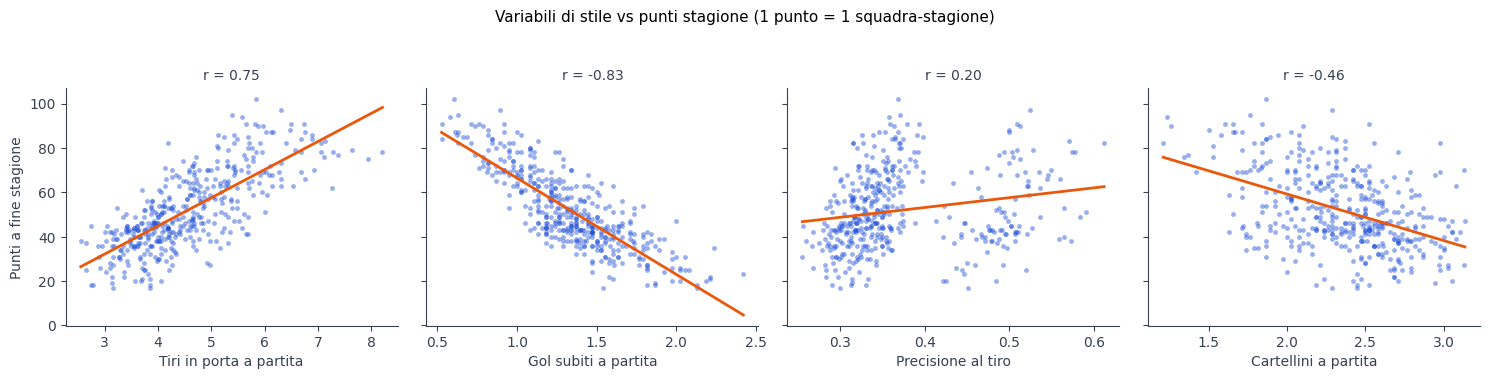

Salvato: 01_eda_vs_punti_con_guida.png + _clean.png


In [3]:
eda_vars = [("tiri_porta_partita","Tiri in porta a partita"), ("gol_subiti","Gol subiti a partita"),
            ("precisione_tiro","Precisione al tiro"), ("cartellini_partita","Cartellini a partita")]

def build_eda():
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
    for ax, (v, lab) in zip(axs, eda_vars):
        r = ts[v].corr(ts["punti_stagione"])
        ax.scatter(ts[v], ts["punti_stagione"], s=12, alpha=.45, color=BLUE, linewidths=0)
        m, q = np.polyfit(ts[v], ts["punti_stagione"], 1)
        xs = np.linspace(ts[v].min(), ts[v].max(), 50)
        ax.plot(xs, m*xs+q, color=ORANGE, lw=2)
        ax.set_xlabel(lab); ax.set_title(f"r = {r:.2f}", fontsize=10, color="#374151")
    axs[0].set_ylabel("Punti a fine stagione")
    fig.suptitle("Variabili di stile vs punti stagione (1 punto = 1 squadra-stagione)", y=1.04, fontsize=11)
    fig.tight_layout()
    return fig
save_both(build_eda, "01_eda_vs_punti")


---
## 4. Normalizzazione delle Variabili (`StandardScaler`)

Peso relativo nella distanza Euclidea PRIMA vs DOPO la normalizzazione:


,prima_scala_originale,dopo_StandardScaler
gol_fatti,0.008,0.125
gol_subiti,0.006,0.125
tiri_partita,0.281,0.125
tiri_porta_partita,0.054,0.125
tiri_subiti_partita,0.256,0.125
precisione_tiro,0.000,0.125
falli_partita,0.387,0.125
cartellini_partita,0.007,0.125


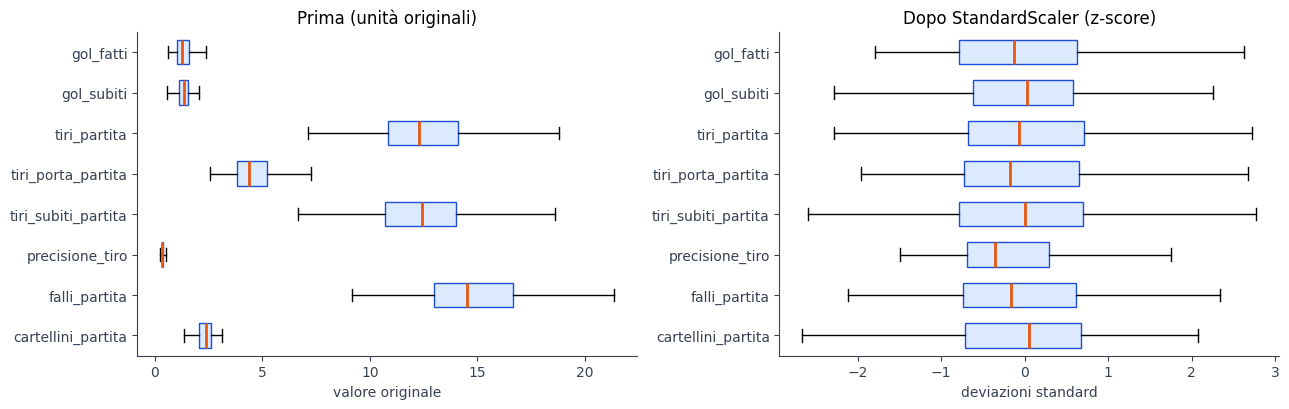

Salvato: 02_normalizzazione_con_guida.png + _clean.png


In [4]:
X_raw = ts[FEATURES].values
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

share_raw = ts[FEATURES].var() / ts[FEATURES].var().sum()
share_std = pd.Series(1/len(FEATURES), index=FEATURES)
print("Peso relativo nella distanza Euclidea PRIMA vs DOPO la normalizzazione:")
display(pd.DataFrame({"prima_scala_originale": share_raw, "dopo_StandardScaler": share_std}).round(3))

def build_scale():
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, data, tt in [(axs[0], ts[FEATURES].values, "Prima (unità originali)"),
                         (axs[1], X, "Dopo StandardScaler (z-score)")]:
        bp = ax.boxplot(data, vert=False, patch_artist=True, widths=.6, showfliers=False,
                        medianprops=dict(color=ORANGE, lw=2))
        for b in bp["boxes"]: b.set(facecolor="#dbeafe", edgecolor=BLUE)
        ax.set_yticklabels(FEATURES); ax.set_title(tt); ax.invert_yaxis()
    axs[0].set_xlabel("valore originale"); axs[1].set_xlabel("deviazioni standard")
    fig.tight_layout()
    return fig
save_both(build_scale, "02_normalizzazione")


---
## 5. K-Means: Metodo del Gomito (WCSS) e Coefficiente di Silhouette

 k  WCSS_inerzia  silhouette
 2        2287.1       0.295
 3        1885.8       0.280
 4        1656.6       0.268
 5        1467.5       0.217
 6        1348.8       0.195

k scelto = 3


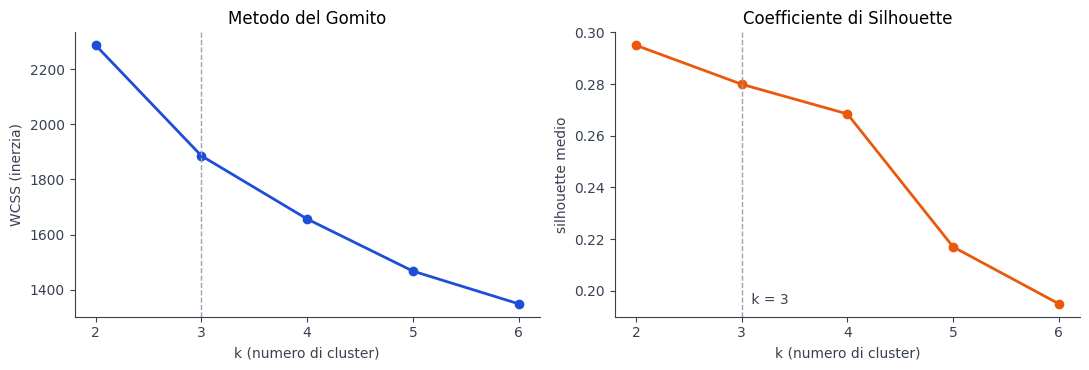

Salvato: 03_gomito_silhouette_con_guida.png + _clean.png


In [5]:
k_range = list(range(2, 7))
wcss, sil = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

K_OPT = int(K_OVERRIDE) if K_OVERRIDE else k_range[int(np.argmax(sil))]
print(pd.DataFrame({"k": k_range, "WCSS_inerzia": np.round(wcss, 1), "silhouette": np.round(sil, 3)}).to_string(index=False))
print(f"\nk scelto = {K_OPT}")

def build_elbow():
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    axs[0].plot(k_range, wcss, "-o", color=BLUE, lw=2)
    axs[0].set_title("Metodo del Gomito"); axs[0].set_xlabel("k (numero di cluster)"); axs[0].set_ylabel("WCSS (inerzia)")
    axs[1].plot(k_range, sil, "-o", color=ORANGE, lw=2)
    axs[1].set_title("Coefficiente di Silhouette"); axs[1].set_xlabel("k (numero di cluster)"); axs[1].set_ylabel("silhouette medio")
    for ax in axs:
        ax.axvline(K_OPT, color="#9ca3af", ls="--", lw=1)
        ax.set_xticks(k_range)
    axs[1].text(K_OPT + .05, min(sil), f" k = {K_OPT}", color="#374151")
    fig.tight_layout()
    return fig
save_both(build_elbow, "03_gomito_silhouette")


---
## 6. K-Means Finale, Profili dei 3 Cluster e Proiezione PCA 2D

PROFILO MEDIO DEI 3 CLUSTER (unità originali + validazione esterna sui punti):


,n_squadre,gol_fatti,gol_subiti,tiri_partita,tiri_porta_partita,tiri_subiti_partita,precisione_tiro,falli_partita,cartellini_partita,punti_stagione
nome_cluster,,,,,,,,,,
Lotta salvezza,215,1.11,1.45,12.00,3.88,13.93,0.32,15.41,2.44,42.73
Metà classifica,76,1.22,1.51,9.62,4.74,10.92,0.49,16.04,2.52,43.53
Big dominanti,129,1.78,1.03,14.83,5.57,10.85,0.38,13.66,2.09,72.04


Lotta salvezza -> esempi più tipici: Udinese 2024/25, Sampdoria 2012/13, Verona 2023/24, Genoa 2015/16, Verona 2015/16
Metà classifica -> esempi più tipici: Verona 2020/21, Genoa 2018/19, Udinese 2006/07, Fiorentina 2020/21, Sassuolo 2018/19
Big dominanti -> esempi più tipici: Atalanta 2023/24, Milan 2011/12, Napoli 2013/14, Milan 2017/18, Inter 2013/14


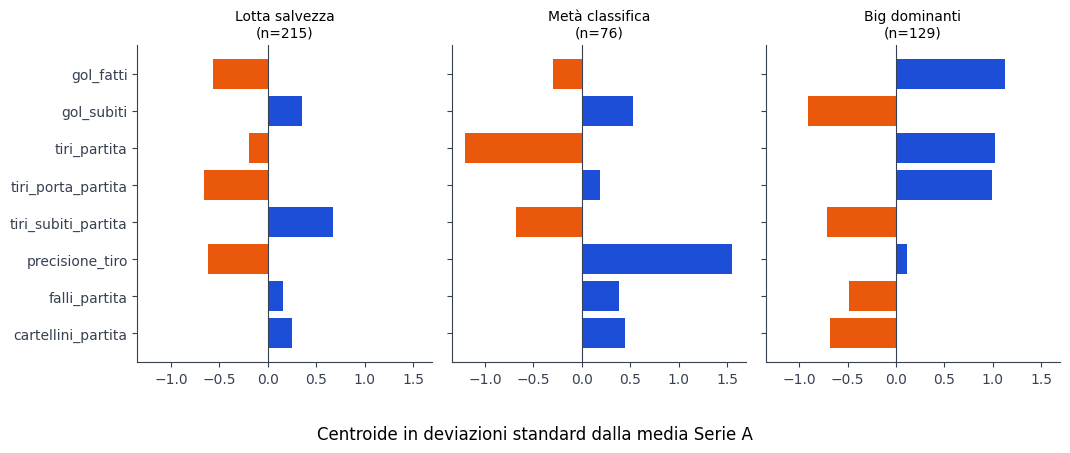

Salvato: 04_profili_centroidi_con_guida.png + _clean.png

PCA 2D: PC1 spiega il 45.4%, PC2 il 21.0% della varianza (totale 66.4%)


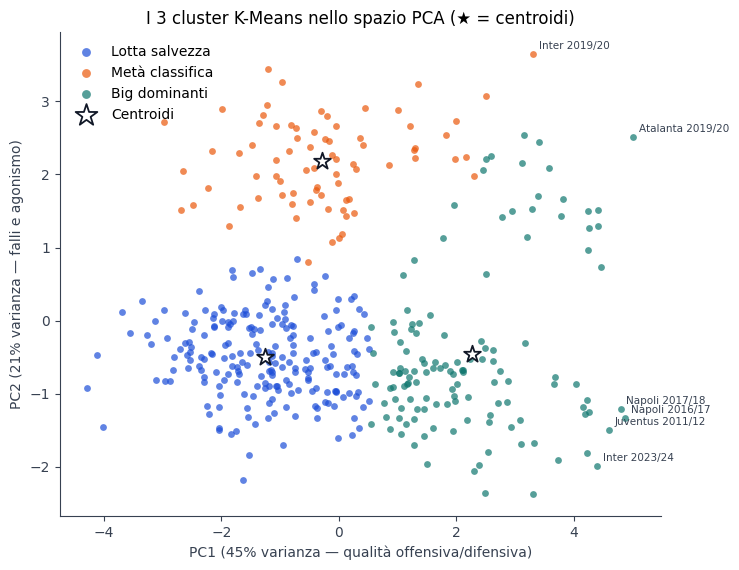

Salvato: 05_pca_kmeans_con_guida.png + _clean.png


In [6]:
km = KMeans(n_clusters=K_OPT, n_init=50, random_state=RANDOM_STATE).fit(X)
ts["_raw"] = km.labels_
ordine = ts.groupby("_raw")["punti_stagione"].mean().sort_values().index
remap = {old: new for new, old in enumerate(ordine)}
ts["cluster"] = ts["_raw"].map(remap)
centroids_z = pd.DataFrame(km.cluster_centers_, columns=FEATURES).rename(index=remap).sort_index()

CLUSTER_NAMES = {0: "Lotta salvezza", 1: "Metà classifica", 2: "Big dominanti"} if K_OPT == 3 else {}
cname = lambda c: CLUSTER_NAMES.get(c, f"Cluster {c}")
ts["nome_cluster"] = ts["cluster"].map(cname)

profilo = ts.groupby("nome_cluster")[FEATURES_STYLE + ["punti_stagione"]].mean().loc[[cname(i) for i in range(K_OPT)]].round(2)
profilo.insert(0, "n_squadre", ts["nome_cluster"].value_counts().loc[[cname(i) for i in range(K_OPT)]])
print("PROFILO MEDIO DEI 3 CLUSTER (unità originali + validazione esterna sui punti):")
display(profilo)

d_cent = np.linalg.norm(X - km.cluster_centers_[ts["_raw"].values], axis=1)
ts["dist_centroide"] = d_cent
for c in range(K_OPT):
    top = ts[ts.cluster == c].nsmallest(5, "dist_centroide")["id"].tolist()
    print(f"{cname(c)} -> esempi più tipici: {', '.join(top)}")

def build_centroids():
    fig, axs = plt.subplots(1, K_OPT, figsize=(3.6 * K_OPT, 4.4), sharey=True, sharex=True)
    axs = np.atleast_1d(axs)
    for c, ax in enumerate(axs):
        vals = centroids_z.loc[c, FEATURES].values
        ax.barh(FEATURES, vals, color=[BLUE if v >= 0 else ORANGE for v in vals])
        ax.axvline(0, color="#374151", lw=.8)
        ax.set_title(f"{cname(c)}\n(n={int((ts.cluster==c).sum())})", fontsize=10)
        ax.invert_yaxis()
    fig.supxlabel("Centroide in deviazioni standard dalla media Serie A", y=-.02)
    fig.tight_layout()
    return fig
save_both(build_centroids, "04_profili_centroidi")

pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X)
ev = pca.explained_variance_ratio_
print(f"\nPCA 2D: PC1 spiega il {ev[0]:.1%}, PC2 il {ev[1]:.1%} della varianza (totale {ev.sum():.1%})")

def build_pca():
    fig, ax = plt.subplots(figsize=(7.5, 5.8))
    for c in range(K_OPT):
        m = ts.cluster.values == c
        ax.scatter(P[m, 0], P[m, 1], s=24, alpha=.7, color=CLUSTER_COLORS[c], label=cname(c), linewidths=0)
    cp = pca.transform(km.cluster_centers_)
    cp = cp[[{v:k for k,v in remap.items()}[c] for c in range(K_OPT)]]
    ax.scatter(cp[:, 0], cp[:, 1], s=160, marker="*", color="white", edgecolor="#111827", lw=1.3, zorder=5, label="Centroidi")
    for i in np.argsort(-np.linalg.norm(P, axis=1))[:6]:
        ax.annotate(ts.id[i], P[i], fontsize=7.5, color="#374151", xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} varianza — qualità offensiva/difensiva)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} varianza — falli e agonismo)")
    ax.set_title("I 3 cluster K-Means nello spazio PCA (★ = centroidi)")
    ax.legend(loc="best", markerscale=1.3)
    fig.tight_layout()
    return fig
save_both(build_pca, "05_pca_kmeans")


---
## 7. DBSCAN: Individuazione delle Stagioni Outlier e Confronto con K-Means

DBSCAN (eps=2.12, min_samples=9): 1 cluster denso, 5 outlier (1.2%)
Adjusted Rand Index (concordanza K-Means vs DBSCAN): 0.007

Le 10 stagioni più estreme (outlier isolati da DBSCAN):


,id,nome_cluster,punti_stagione,gol_fatti,gol_subiti,tiri_porta_partita
6,Juventus 2005/06,Big dominanti,87,1.89,0.61,6.11
280,Atalanta 2019/20,Big dominanti,78,2.58,1.26,8.21
11,Milan 2005/06,Big dominanti,88,2.24,0.82,6.47
4,Fiorentina 2005/06,Big dominanti,71,1.78,1.08,5.42
5,Inter 2005/06,Big dominanti,76,1.79,0.79,7.11


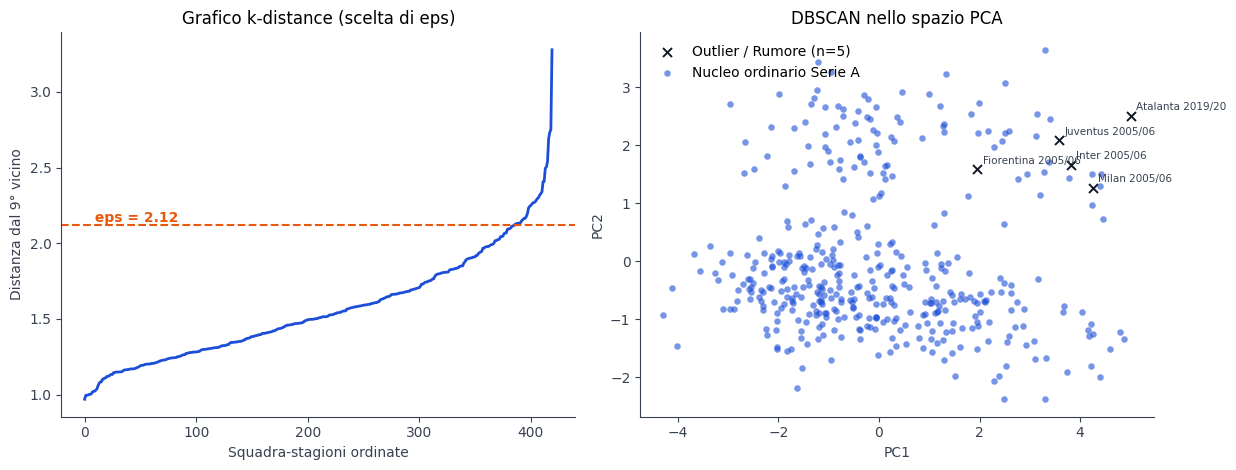

Salvato: 06_dbscan_outlier_con_guida.png + _clean.png


In [7]:
min_samples = len(FEATURES) + 1
kdist = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1])
eps = float(EPS_OVERRIDE) if EPS_OVERRIDE else float(np.percentile(kdist, 92))

db = DBSCAN(eps=eps, min_samples=min_samples).fit(X)
ts["dbscan"] = db.labels_
n_cl, n_noise = len(set(db.labels_)) - (-1 in db.labels_), int((db.labels_ == -1).sum())
print(f"DBSCAN (eps={eps:.2f}, min_samples={min_samples}): {n_cl} cluster denso, {n_noise} outlier ({n_noise/len(ts):.1%})")
print(f"Adjusted Rand Index (concordanza K-Means vs DBSCAN): {adjusted_rand_score(ts.cluster, ts.dbscan):.3f}")

outl = ts[ts.dbscan == -1].copy()
print("\nLe 10 stagioni più estreme (outlier isolati da DBSCAN):")
display(outl.sort_values("dist_centroide", ascending=False)[["id","nome_cluster","punti_stagione","gol_fatti","gol_subiti","tiri_porta_partita"]].head(10).round(2))

def build_dbscan():
    fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8))
    axs[0].plot(kdist, color=BLUE, lw=2)
    axs[0].axhline(eps, color=ORANGE, ls="--"); axs[0].text(5, eps, f" eps = {eps:.2f}", va="bottom", color=ORANGE, fontweight="bold")
    axs[0].set_xlabel("Squadra-stagioni ordinate"); axs[0].set_ylabel(f"Distanza dal {min_samples}° vicino")
    axs[0].set_title("Grafico k-distance (scelta di eps)")
    for lab in sorted(set(db.labels_)):
        m = db.labels_ == lab
        if lab == -1:
            axs[1].scatter(P[m, 0], P[m, 1], s=42, marker="x", color=NOISE_COLOR, label=f"Outlier / Rumore (n={n_noise})", lw=1.4)
        else:
            axs[1].scatter(P[m, 0], P[m, 1], s=22, alpha=.6, color=BLUE, label="Nucleo ordinario Serie A", linewidths=0)
    for i in np.where(db.labels_ == -1)[0][:6]:
        axs[1].annotate(ts.id[i], P[i], fontsize=7.5, xytext=(4, 4), textcoords="offset points", color="#374151")
    axs[1].set_xlabel("PC1"); axs[1].set_ylabel("PC2"); axs[1].set_title("DBSCAN nello spazio PCA"); axs[1].legend()
    fig.tight_layout()
    return fig
save_both(build_dbscan, "06_dbscan_outlier")


---
## 8. Validazione Esterna (Punti Reali per Cluster) ed Esportazione ZIP

In [8]:
import shutil

print("Validazione esterna — Distribuzione punti reali nei 3 cluster (nascosti durante l'addestramento):")
display(ts.groupby("nome_cluster")["punti_stagione"].describe().loc[[cname(i) for i in range(K_OPT)]].round(1))

cols_out = ["id","squadra","stagione","cluster","nome_cluster","dbscan","punti_stagione"] + FEATURES_STYLE
ts[cols_out].to_csv(f"{DATA_DIR}/cluster_assegnazioni.csv", index=False)

shutil.make_archive("progetto_serie_a_finale", "zip", EXPORT_DIR)
print("\nArchivio 'progetto_serie_a_finale.zip' creato con successo!")

try:
    from google.colab import files
    files.download("progetto_serie_a_finale.zip")
    print("Download automatico avviato.")
except Exception:
    print("File pronto in locale: progetto_serie_a_finale.zip")


Validazione esterna — Distribuzione punti reali nei 3 cluster (nascosti durante l'addestramento):


,count,mean,std,min,25%,50%,75%,max
nome_cluster,,,,,,,,
Lotta salvezza,215.0,42.7,10.5,17.0,36.0,43.0,49.5,68.0
Metà classifica,76.0,43.5,12.5,17.0,38.0,42.0,49.2,82.0
Big dominanti,129.0,72.0,11.1,47.0,64.0,71.0,80.0,102.0



Archivio 'progetto_serie_a_finale.zip' creato con successo!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download automatico avviato.
